# Tomorrow's Connecticut demand with uncertainty bands: GEFS ensemble + quantile forest

**Dr. Dave · University of Connecticut** · demo, October 2026

A forecast without a range hides two kinds of doubt:

| doubt | where it comes from | how we measure it here |
|---|---|---|
| **weather** | tomorrow's weather itself is uncertain | NOAA's **GEFS ensemble**: the same global model run 30 times from slightly different starting points |
| **model** | even with perfect weather, our load model isn't exact | a **quantile random forest**: instead of one number, it predicts the 5th, 10th, ... 95th percentile |

We feed every GEFS run through the quantile forest and pool the results, so the final band carries both kinds of doubt.
Everything comes from free, public data; the forecasts are downloaded with [hefty](https://github.com/williamhobbs/hefty)
(Will Hobbs, Southern Company).

Runtime -> Run all (about 6 minutes: the 30-member ensemble is the slow part).

## Setup
`hefty` needs Python 3.12 or newer (Colab has it). If Colab asks to restart after the install, click **Restart**, then **Run all**.

In [1]:
try:
    import hefty
    import quantile_forest
    print('hefty and quantile-forest already installed')
except ImportError:
    !pip install -q hefty quantile-forest

hefty and quantile-forest already installed


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from hefty.solar import get_solar_forecast, get_solar_forecast_ensemble
from hefty.utilities import adjust_forecast_datetimes
from quantile_forest import RandomForestQuantileRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

In [3]:
SETTINGS = {
    'site': 'Bradley Airport (BDL)',
    'latitude': 41.9389,
    'longitude': -72.6832,
    'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
    'quantiles': [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95],
    'seed': 5509,
}
SETTINGS

{'site': 'Bradley Airport (BDL)',
 'latitude': 41.9389,
 'longitude': -72.6832,
 'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
 'quantiles': [0.05,
  0.1,
  0.15,
  0.2,
  0.25,
  0.3,
  0.35,
  0.4,
  0.45,
  0.5,
  0.55,
  0.6,
  0.65,
  0.7,
  0.75,
  0.8,
  0.85,
  0.9,
  0.95],
 'seed': 5509}

## Step 1: train a quantile forest on three years of history
Inputs: the clock (hour, day of week, month), temperature, and sunlight (a clear sky's sunlight from pvlib, dimmed by Bradley's
reported cloud cover). A quantile forest is a normal random forest that keeps every training value in its leaves, so it can
report percentiles instead of only the average.

In [4]:
load = pd.read_csv(SETTINGS['load_url'])
load['hour_utc'] = pd.to_datetime(load['hour_utc'], utc=True)
load = load.set_index('hour_utc')
local = load.index.tz_convert('America/New_York')
load['hour_local'] = local.hour
load['day_of_week'] = local.dayofweek
load['month'] = local.month
site = pvlib.location.Location(SETTINGS['latitude'], SETTINGS['longitude'])
clear = site.get_clearsky(load.index + pd.Timedelta(minutes=30), model='ineichen')
load['sun'] = clear['ghi'].values * (1 - 0.75 * (load['cloud_cover_pct'] / 100) ** 3.4)
load = load.dropna(subset=['sun'])

FEATURES = ['hour_local', 'day_of_week', 'month', 'temp_f', 'sun']
X_train = load[FEATURES]
y_train = load['load_mw']
print('X_train', X_train.shape, '| y_train', y_train.shape)

qrf = RandomForestQuantileRegressor(n_estimators=200, min_samples_leaf=20, random_state=SETTINGS['seed'], n_jobs=-1)
qrf.fit(X_train, y_train)
print('quantile forest trained:', qrf.n_estimators, 'trees')

X_train (26304, 5) | y_train (26304,)


quantile forest trained: 200 trees


## Step 2: tomorrow's weather, 30 times over (GEFS)
`get_ens_temp=True` gives every ensemble member its own temperature (without it, hefty reuses one temperature for all members to
save time - fine for solar, not for load). One table comes back: one row per member per hour.

In [5]:
now = pd.Timestamp.now(tz='UTC').floor('h').tz_localize(None)
tomorrow = pd.Timestamp.now(tz='America/New_York').normalize() + pd.Timedelta(days=1)
hours = pd.date_range(tomorrow.tz_convert('UTC'), periods=24, freq='h')
lead = int((hours[0].tz_localize(None) - now) / pd.Timedelta(hours=1))
init, run_length, lead_start = adjust_forecast_datetimes(now, 24, lead, model='gefs')
print('tomorrow =', tomorrow.date(), '| newest GEFS run available:', init)

t0 = time.time()
ens = get_solar_forecast_ensemble(SETTINGS['latitude'], SETTINGS['longitude'], init, run_length, lead_start,
                                  model='gefs', get_ens_temp=True)
ens.index = ens.index.floor('h')
print('took', round(time.time() - t0), 's | ensemble table shape:', ens.shape)
print('members:', ens['member'].nunique(), '| hours per member:', len(ens) // ens['member'].nunique())
ens.head()

tomorrow = 2026-10-17 | newest GEFS run available: 2026-10-16 12:00:00+00:00


took 163 s | ensemble table shape: (810, 11)
members: 30 | hours per member: 27


,temp_air,wind_speed,wind_direction,lead_time,ghi_csi,ghi,dni,dhi,ghi_clear,member,point
valid_time,,,,,,,,,,,
2026-10-17 03:00:00+00:00,12.350612,2.0,0.0,15.5,0.0,0.0,0.0,0.0,NaN,1,0
2026-10-17 04:00:00+00:00,11.239578,2.0,0.0,16.5,0.0,0.0,0.0,0.0,NaN,1,0
2026-10-17 05:00:00+00:00,10.128545,2.0,0.0,17.5,0.0,0.0,0.0,0.0,NaN,1,0
2026-10-17 06:00:00+00:00,9.023758,2.0,0.0,18.5,0.0,0.0,0.0,0.0,NaN,1,0
2026-10-17 07:00:00+00:00,7.925217,2.0,0.0,19.5,0.0,0.0,0.0,0.0,NaN,1,0


In [6]:
# the same 24 hours of tomorrow for every member: rows = members, columns = hours
local_hours = hours.tz_convert('America/New_York')
members = sorted(ens['member'].unique())
temp_table = pd.DataFrame(index=members, columns=local_hours, dtype=float)
sun_table = pd.DataFrame(index=members, columns=local_hours, dtype=float)
for m in members:
    e = ens[ens['member'] == m]
    e = e[~e.index.duplicated()].reindex(hours)
    temp_table.loc[m] = e['temp_air'].values * 9 / 5 + 32
    sun_table.loc[m] = e['ghi'].values
print('temperature table (members x hours):', temp_table.shape)
temp_table.iloc[:5, :8].round(1)

temperature table (members x hours): (30, 24)


,2026-10-17 00:00:00-04:00,2026-10-17 01:00:00-04:00,2026-10-17 02:00:00-04:00,2026-10-17 03:00:00-04:00,2026-10-17 04:00:00-04:00,2026-10-17 05:00:00-04:00,2026-10-17 06:00:00-04:00,2026-10-17 07:00:00-04:00
1,52.2,50.2,48.2,46.3,44.3,43.1,42.8,42.4
2,49.6,47.9,46.7,46.2,45.7,45.1,44.5,43.8
3,55.0,52.9,51.0,49.3,47.6,46.1,44.7,43.3
4,54.0,51.5,49.7,48.5,47.4,45.9,44.2,42.5
5,51.4,49.6,48.0,46.4,44.8,43.8,43.5,43.2


For comparison: the single, sharper HRRR forecast (3 km instead of GEFS's 25 km).

In [7]:
init_h, run_h, lead_h = adjust_forecast_datetimes(now, 24, lead, model='hrrr')
hrrr = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], init_h, run_length=run_h, lead_time_to_start=lead_h, model='hrrr')
hrrr.index = hrrr.index.floor('h')
hrrr = hrrr[~hrrr.index.duplicated()].reindex(hours)
hrrr_temp_f = hrrr['temp_air'].values * 9 / 5 + 32
print('HRRR run', init_h, '| shape', hrrr.shape)

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F16 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F17 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F18 ┊ GRIB2 @ aws ┊ IDX @ local


...

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F39 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 12:00 UTC F40 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


HRRR run 2026-10-16 12:00:00+00:00 | shape (24, 12)


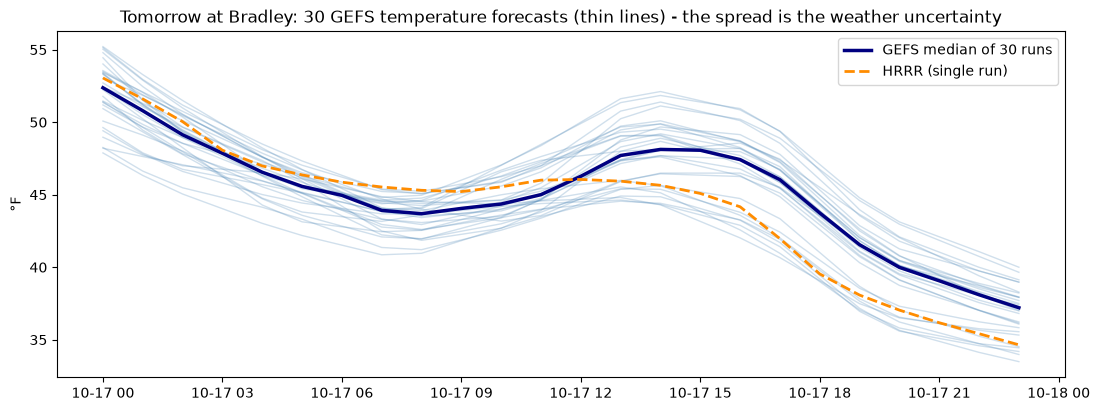

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for m in members:
    ax.plot(local_hours, temp_table.loc[m], color='steelblue', alpha=0.25, linewidth=1)
ax.plot(local_hours, temp_table.median(), color='navy', linewidth=2.5, label='GEFS median of 30 runs')
ax.plot(local_hours, hrrr_temp_f, color='darkorange', linewidth=2, linestyle='--', label='HRRR (single run)')
ax.set_ylabel('°F')
ax.set_title('Tomorrow at Bradley: 30 GEFS temperature forecasts (thin lines) - the spread is the weather uncertainty')
ax.legend()
plt.show()

## Step 3: every member through the quantile forest
For each of the 30 weather runs, the forest predicts 19 percentiles of load (5th to 95th). Pooling them gives 570 plausible
values per hour, and their 10th, 50th and 90th percentiles are the final band. For contrast, the **weather-only** band uses just
each member's median - what you'd get if the load model were perfect.

In [9]:
clock = pd.DataFrame({'hour_local': local_hours.hour, 'day_of_week': local_hours.dayofweek, 'month': local_hours.month}, index=hours)
pooled = []
member_medians = []
for m in members:
    X_member = clock.copy()
    X_member['temp_f'] = temp_table.loc[m].values
    X_member['sun'] = sun_table.loc[m].values
    q = qrf.predict(X_member[FEATURES], quantiles=SETTINGS['quantiles'])      # shape (24 hours, 19 percentiles)
    pooled.append(q)
    member_medians.append(q[:, SETTINGS['quantiles'].index(0.5)])
pooled = np.concatenate(pooled, axis=1)
member_medians = np.array(member_medians)
print('pooled predictions (hours x values):', pooled.shape, '| member medians (members x hours):', member_medians.shape)

X_hrrr = clock.copy()
X_hrrr['temp_f'] = hrrr_temp_f
X_hrrr['sun'] = hrrr['ghi'].values

bands = pd.DataFrame(index=local_hours)
bands['p10'] = np.percentile(pooled, 10, axis=1)
bands['median'] = np.percentile(pooled, 50, axis=1)
bands['p90'] = np.percentile(pooled, 90, axis=1)
bands['weather only p10'] = np.percentile(member_medians, 10, axis=0)
bands['weather only p90'] = np.percentile(member_medians, 90, axis=0)
bands['HRRR median'] = qrf.predict(X_hrrr[FEATURES], quantiles=0.5)
bands.round(0)

pooled predictions (hours x values): (24, 570) | member medians (members x hours): (30, 24)


,p10,median,p90,weather only p10,weather only p90,HRRR median
2026-10-17 00:00:00-04:00,2138.0,2201.0,2294.0,2201.0,2204.0,2201.0
2026-10-17 01:00:00-04:00,2018.0,2095.0,2184.0,2095.0,2096.0,2096.0
2026-10-17 02:00:00-04:00,1972.0,2034.0,2113.0,2034.0,2034.0,2034.0
2026-10-17 03:00:00-04:00,1968.0,2026.0,2106.0,2026.0,2028.0,2026.0
2026-10-17 04:00:00-04:00,1967.0,2044.0,2122.0,2044.0,2051.0,2044.0
2026-10-17 05:00:00-04:00,2032.0,2138.0,2299.0,2124.0,2205.0,2125.0
2026-10-17 06:00:00-04:00,2170.0,2298.0,2523.0,2266.0,2359.0,2266.0
2026-10-17 07:00:00-04:00,2229.0,2421.0,2667.0,2382.0,2464.0,2382.0
2026-10-17 08:00:00-04:00,2402.0,2615.0,2956.0,2530.0,2692.0,2554.0
2026-10-17 09:00:00-04:00,2484.0,2761.0,3045.0,2638.0,2884.0,2724.0


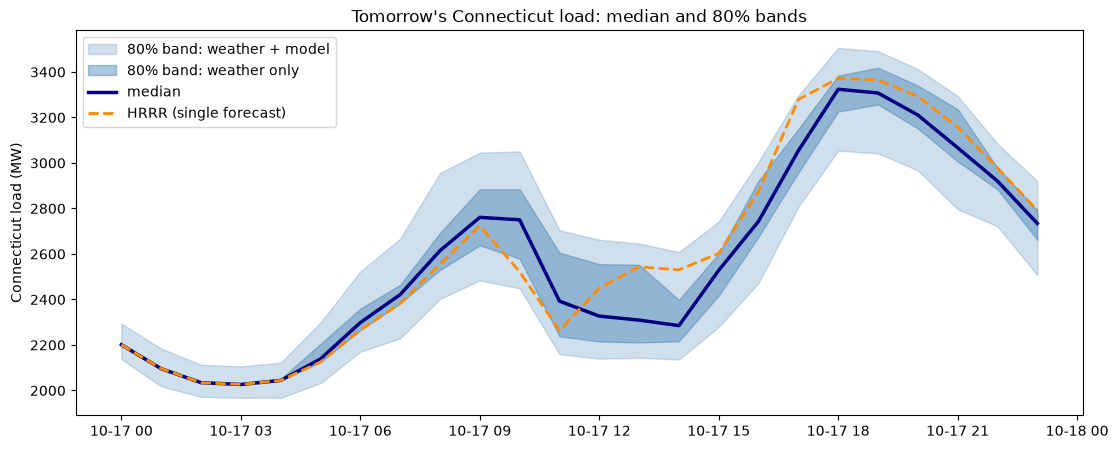

peak hour: 06 PM | median 3324 MW | 80% band 3054 - 3506 MW


In [10]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(local_hours, bands['p10'], bands['p90'], color='steelblue', alpha=0.25, label='80% band: weather + model')
ax.fill_between(local_hours, bands['weather only p10'], bands['weather only p90'], color='steelblue', alpha=0.45, label='80% band: weather only')
ax.plot(local_hours, bands['median'], color='navy', linewidth=2.5, label='median')
ax.plot(local_hours, bands['HRRR median'], color='darkorange', linewidth=2, linestyle='--', label='HRRR (single forecast)')
ax.set_ylabel('Connecticut load (MW)')
ax.set_title('Tomorrow\'s Connecticut load: median and 80% bands')
ax.legend(loc='upper left')
plt.show()

peak = bands['median'].idxmax()
print('peak hour:', peak.strftime('%I %p'), '| median', round(bands.loc[peak, 'median']), 'MW',
      '| 80% band', round(bands.loc[peak, 'p10']), '-', round(bands.loc[peak, 'p90']), 'MW')

## How to read it, and how to grade it tomorrow
- **Dark band (weather only):** narrow overnight, when all 30 runs agree; widest in the evening, when the cold arrives at
  different speeds in different runs.
- **Light band (weather + model):** adds the load model's own error. Usually the bigger of the two - a reminder that a perfect
  weather forecast still doesn't give a perfect load forecast.
- **Grading a band:** an honest 80% band should contain the actual load about 80% of the hours. Too narrow = overconfident,
  too wide = useless. Check tomorrow against ISO New England's actual Connecticut load (ISO Express, zonal information);
  over many days, the *coverage* and the pinball (quantile) loss are the scores to compare.

Things students could change: swap `model='gefs'` for `'ifs_ens'` (ECMWF's 51-member ensemble), add lagged-temperature windows,
train on GEFS forecasts instead of observed weather, or weight several Connecticut locations.